# Design a working controller

## 1. Set up the notebook

### 1.1 Do imports

Do imports.

In [933]:
import numpy as np
import sympy as sym
from scipy import linalg
import matplotlib.pyplot as plt
from ae483.tools import *
from ae483.mytools import *
from ae483.design import *

### 1.2 Create an LQR solver

Define a function that solves the linear quadratic regulator (LQR) problem.

In [934]:
def lqr(A, B, Q, R):
    P = linalg.solve_continuous_are(A, B, Q, R)
    K = linalg.inv(R) @  B.T @ P
    return K

## 2. Derive equations of motion

### 2.1 Define symbolic variables

Define states.

In [935]:
# components of position (meters)
p_x, p_y, p_z = sym.symbols('p_x, p_y, p_z')

# yaw, pitch, and roll angles (radians)
psi, theta, phi = sym.symbols('psi, theta, phi')

# components of linear velocity (meters / second)
v_x, v_y, v_z = sym.symbols('v_x, v_y, v_z')

# components of angular velocity (radians / second)
w_x, w_y, w_z = sym.symbols('w_x, w_y, w_z')

# torque states
tau_x, tau_y = sym.symbols('tau_x, tau_y')

# error states
e_x, e_y, e_z = sym.symbols('e_x, e_y, e_z')

Define inputs.

In [936]:
# components of net rotor torque
tau_x_cmd, tau_y_cmd, tau_z = sym.symbols('tau_x_cmd, tau_y_cmd, tau_z')

# net rotor force
f_z = sym.symbols('f_z')

Define parameters.

In [937]:
m, J_x, J_y, J_z, g, T_F = sym.symbols('m, J_x, J_y, J_z, g, T_F')

Create the linear velocity vector $v^B_{W, B}$ and the angular velocity vector $w^B_{W, B}$, both written in the coordinates of the body frame.

In [938]:
v_inB_ofWB = sym.Matrix([v_x, v_y, v_z])
w_inB_ofWB = sym.Matrix([w_x, w_y, w_z])

Create moment of inertia matrix (in coordinates of the body frame).

In [939]:
J_inB = sym.diag(J_x, J_y, J_z)

### 2.2 Define kinematics of orientation

#### 2.2.1 Rotation matrix in terms of yaw, pitch, roll angles

Define individual rotation matrices.

In [940]:
Rz = sym.Matrix([[sym.cos(psi), -sym.sin(psi), 0],
                 [sym.sin(psi), sym.cos(psi), 0],
                 [0, 0, 1]])

Ry = sym.Matrix([[sym.cos(theta), 0, sym.sin(theta)],
                 [0, 1, 0],
                 [-sym.sin(theta), 0, sym.cos(theta)]])

Rx = sym.Matrix([[1, 0, 0],
                 [0, sym.cos(phi), -sym.sin(phi)],
                 [0, sym.sin(phi), sym.cos(phi)]])

Apply sequential transformation to compute the rotation matrix that describes the orientation of the drone (i.e., of frame $B$ in the coordinates of frame $W$).

In [941]:
R_inW_ofB = Rz @ Ry @ Rx

#### 2.2.2 Map from angular velocity to angular rates

Recall that

$$\begin{bmatrix} \dot{\psi} \\ \dot{\theta} \\ \dot{\phi} \end{bmatrix} = N w_{W, B}^{B}$$

for some matrix $N$. Here is how to compute that matrix for a ZYX (yaw, pitch, roll) Euler angle sequence.  First, we compute its inverse:

In [942]:
Ninv = sym.Matrix.hstack((Ry @ Rx).T @ sym.Matrix([0, 0, 1]),
                              (Rx).T @ sym.Matrix([0, 1, 0]),
                                       sym.Matrix([1, 0, 0]))

Then, we compute $N$ by taking the inverse of $N^{-1}$:

In [943]:
N = sym.simplify(Ninv.inv())

### 2.3 Define equations of motion

Forces.

In [944]:
f_inB = R_inW_ofB.T @ sym.Matrix([0, 0, -m * g]) + sym.Matrix([0, 0, f_z])

Torques.

In [945]:
tau_inB = sym.Matrix([tau_x, tau_y, tau_z])

Time delay

In [946]:
time_delay = sym.Matrix([(1/T_F) * (tau_x_cmd - tau_x), 
                         (1/T_F) * (tau_y_cmd - tau_y)])

Errors

In [947]:
error = sym.Matrix([p_x, p_y, p_z])

Create equations of motion.

In [948]:
f_sym = sym.Matrix.vstack(
    R_inW_ofB @ v_inB_ofWB,
    N @ w_inB_ofWB,
    (1 / m) * (f_inB - w_inB_ofWB.cross(m * v_inB_ofWB)),
    J_inB.inv() @ (tau_inB - w_inB_ofWB.cross(J_inB @ w_inB_ofWB)),
    time_delay,
    error
)

Show the right-hand side of the equations of motion, which have the form

$$\dot{s} = f(s, i, p)$$

for states

$$
s = \begin{bmatrix} p_x \\ p_y \\ p_z \\ \psi \\ \theta \\ \phi \\ v_x \\ v_y \\ v_z \\ w_x \\ w_y \\ w_z \\ \tau_x \\ \tau_y \\e_x \\e_y \\e_z \end{bmatrix},
$$

inputs
$$
i = \begin{bmatrix} \tau_{x,cmd} \\ \tau_{y,cmd} \\ \tau_z \\ f_z \end{bmatrix},
$$

and parameters
$$
p = \begin{bmatrix} m \\ J_x \\ J_y \\ J_z \\ g \end{bmatrix}.
$$

In [949]:
f_sym

Matrix([
[ v_x*cos(psi)*cos(theta) + v_y*(sin(phi)*sin(theta)*cos(psi) - sin(psi)*cos(phi)) + v_z*(sin(phi)*sin(psi) + sin(theta)*cos(phi)*cos(psi))],
[v_x*sin(psi)*cos(theta) + v_y*(sin(phi)*sin(psi)*sin(theta) + cos(phi)*cos(psi)) + v_z*(-sin(phi)*cos(psi) + sin(psi)*sin(theta)*cos(phi))],
[                                                                       -v_x*sin(theta) + v_y*sin(phi)*cos(theta) + v_z*cos(phi)*cos(theta)],
[                                                                                         w_y*sin(phi)/cos(theta) + w_z*cos(phi)/cos(theta)],
[                                                                                                               w_y*cos(phi) - w_z*sin(phi)],
[                                                                                   w_x + w_y*sin(phi)*tan(theta) + w_z*cos(phi)*tan(theta)],
[                                                                                                (g*m*sin(theta) + m*v_y*w_z - m*v_z*w_y)/m

## 3. Derive state-space model

### 3.1 Choose equilibrium point

An equilibrium point of the nonlinear system is a choice of states $s_\text{eq}$ and inputs $i_\text{eq}$ — along with constant parameters $p_\text{eq}$ — for which

$$0 = f(s_\text{eq}, i_\text{eq}, p_\text{eq}).$$

Create a list of states, inputs, and parameters as symbolic variables.

In [950]:
s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y, e_x, e_y, e_z]
i = [tau_x_cmd, tau_y_cmd, tau_z, f_z]
p = [m, J_x, J_y, J_z, g, T_F]

Create a list of states to track as symbolic variables. These are states whose desired values will be specified by a client.

In [951]:
s_with_des = [p_x, p_y, p_z]

Create a function that evaluates $f(\cdot)$ at particular values of $s$, $i$, and $p$.

In [952]:
f = sym.lambdify(s + i + p, f_sym)

Define constants.

In [953]:
# Mass
m = 32*1e-3 # <-- FIXME

# Principle moments of inertia
J_x = 1.63e-05  # <-- FIXME
J_y = 1.61e-05  # <-- FIXME
J_z = 3.02e-05  # <-- FIXME

# Acceleration of gravity
g = 9.81

# Time delay constant
T_F = 0.066

Create a list of parameter values in the **same order** as the symbolic list. These are the parameter estimates we found in our experiments. They are not choices. (We use the subscript `_eq` to be consistent with what follows, and could say "parameter values *at equilibrium*," but don't be misled. These parameter values are *given* and are *constant* - again, they aren't choices.)

In [954]:
p_eq = [m, J_x, J_y, J_z, g, T_F]

Create a list of state and input values at equilibrium in the **same order** as the symbolic lists.

In [955]:
# s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y, e_x, e_y, e_z]
# i = [tau_x, tau_y, tau_z, f_z]
# p = [m, J_x, J_y, J_z, g, T_F]

s_eq = [0., 0., 0., 0., np.pi/6., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.] # <-- FIXME
i_eq = [0., 0., 0., m*g]                                 # <-- FIXME



Evaluate the equations of motion at the equilibrium point — if it actually *is* an equilibrium point, then the result should be an array of zeros:

In [956]:
print(f(*s_eq, *i_eq, *p_eq))
# assert(np.allclose(f(*s_eq, *i_eq, *p_eq), 0.))

[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [4.905     ]
 [0.        ]
 [1.31429079]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]


Note that this equilibrium point would remain an equilibrium point for any choice of `p_x`, `p_y`, and `p_z` — that is one thing that allows the controller to track desired values of these variables.

### 3.2 Compute A and B

We want to find

$$
A = \frac{\partial f}{\partial s}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}
\qquad\text{and}\qquad
B = \frac{\partial f}{\partial i}\biggr\vert_{(s, i, p) = (s_\text{eq}, i_\text{eq}, p_\text{eq})}.
$$

First, we compute each Jacobian (i.e., each matrix of partial derivatives) in symbolic form.

In [957]:
A_sym = f_sym.jacobian(s)
B_sym = f_sym.jacobian(i)

Then, we create functions that allow us to evaluate these Jacobians at particular values of $s$, $i$, and $p$.

In [958]:
A_num = sym.lambdify(s + i + p, A_sym)
B_num = sym.lambdify(s + i + p, B_sym)

Finally, we plug in our equilibrium point.

In [959]:
A = A_num(*s_eq, *i_eq, *p_eq)
B = B_num(*s_eq, *i_eq, *p_eq)

Show $A$ (formatted nicely).

In [960]:
A_str = np.array2string(A,
                        formatter={'float_kind': lambda x: f'{x:6.3f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'A = {A_str}')

A = [[ 0.000  0.000  0.000  0.000  0.000  0.000  0.866  0.000  0.500  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000 -0.000  0.000 -0.500  0.000  0.866  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.155  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000 -0.000  0.000  0.000  0.000  0.000  1.000 -0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  1.000  0.000  0.577  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  8.496  0.000  0.000  0.000 -0.000  0.000 -0.000  0.000  0.000  0.000  0.000  0.000  0.000]
     [ 0.000  0.000  0.000  0.000  0.000 -8.496 -0.000  0.000  0.000  0.000  0.000 -0.000  0.000  0.000  0.000  0.000 

Show $B$ (formatted nicely).

In [961]:
B_str = np.array2string(B,
                        formatter={'float_kind': lambda x: f'{x:11.3f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'B = {B_str}')

B = [[      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000      31.250]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000   33112.583       0.000]
     [     15.152       0.000       0.000       0.000]
     [      0.000      15.152       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]
     [      0.000       0.000       0.000       0.000]]


The state-space system is described by

$$ \dot{x} = Ax + Bu $$

where

$$ x = s - s_\text{eq} $$

and

$$ u = i - i_\text{eq}. $$

Note that $A$ and $B$ would remain the same for any choice of `p_x`, `p_y`, and `p_z` — that is another thing that allows the controller to track desired values of these variables.

## 4. Design method of power distribution

Define constants.

In [962]:
k_F = 1.46e-06 # <-- FIXME
k_M = 6.98e-09 # <-- FIXME
l = 3.1819805153 * 1e-2   # <-- FIXME

Define the matrix $P$ that maps motor power commands ($m_1$, $m_2$, $m_3$, $m_4$) to inputs ($\tau_x$, $\tau_y$, $\tau_z$, $f_z$).

In [963]:
P = np.array([[ -l * k_F, -l * k_F,  l * k_F,  l * k_F  ],
              [ -l * k_F, l * k_F,   l * k_F,  -l * k_F ],
              [ -k_M,     k_M,       -k_M,     k_M      ],
              [ k_F,      k_F,       k_F,      k_F      ]])

Compute the matrix $P^{-1}$ that maps inputs to motor power commands.

In [964]:
Pinv = linalg.inv(P)

Show the matrix $P^{-1}$ (formatted nicely).

In [965]:
Pinv_str = np.array2string(Pinv,
                           formatter={'float_kind': lambda x: f'{x:12.1f}'},
                           prefix='         ',
                           max_line_width=np.inf)

print(f'inv(P) = {Pinv_str}')

inv(P) = [[  -5381330.1   -5381330.1  -35816618.9     171232.9]
          [  -5381330.1    5381330.1   35816618.9     171232.9]
          [   5381330.1    5381330.1  -35816618.9     171232.9]
          [   5381330.1   -5381330.1   35816618.9     171232.9]]


Print code that implements the method of power distribution in C (compare this code to $P^{-1}$).

In [966]:
export_power_distribution(
    Pinv,
    i=i,
    limiter='limitUint16',
    suffix='f',
    line_ending=';',
)

m_1 = limitUint16( -5381330.1f * tau_x_cmd -5381330.1f * tau_y_cmd -35816618.9f * tau_z + 171232.9f * f_z );
m_2 = limitUint16( -5381330.1f * tau_x_cmd + 5381330.1f * tau_y_cmd + 35816618.9f * tau_z + 171232.9f * f_z );
m_3 = limitUint16( 5381330.1f * tau_x_cmd + 5381330.1f * tau_y_cmd -35816618.9f * tau_z + 171232.9f * f_z );
m_4 = limitUint16( 5381330.1f * tau_x_cmd -5381330.1f * tau_y_cmd + 35816618.9f * tau_z + 171232.9f * f_z );


## 5. Design, implement, and test a sequence of controllers

Decide which inputs will depend on which states — we call this the **gain structure**.

In [967]:
# Find the gain structure
structure = gain_structure(A, B, s, i)

# Show the gain structure
structure

{'tau_x_cmd': ['p_y', 'psi', 'phi', 'v_y', 'w_x', 'w_z', 'tau_x', 'e_y'],
 'tau_y_cmd': ['p_x',
  'p_z',
  'theta',
  'v_x',
  'v_z',
  'w_y',
  'tau_y',
  'e_x',
  'e_z'],
 'tau_z': ['p_y', 'psi', 'phi', 'v_y', 'w_x', 'w_z', 'tau_x', 'e_y'],
 'f_z': ['p_x', 'p_z', 'theta', 'v_x', 'v_z', 'w_y', 'tau_y', 'e_x', 'e_z']}

Print code that defines all gains in C, with placeholder values.

In [968]:
export_declarations(structure)

// Gains (these are set by flight.py - do not edit the values here)
static float eq_tau_x_cmd = 0.0f;
static float k_tau_x_cmd_p_y = 0.0f;
static float k_tau_x_cmd_psi = 0.0f;
static float k_tau_x_cmd_phi = 0.0f;
static float k_tau_x_cmd_v_y = 0.0f;
static float k_tau_x_cmd_w_x = 0.0f;
static float k_tau_x_cmd_w_z = 0.0f;
static float k_tau_x_cmd_tau_x = 0.0f;
static float k_tau_x_cmd_e_y = 0.0f;
static float eq_tau_y_cmd = 0.0f;
static float k_tau_y_cmd_p_x = 0.0f;
static float k_tau_y_cmd_p_z = 0.0f;
static float k_tau_y_cmd_theta = 0.0f;
static float k_tau_y_cmd_v_x = 0.0f;
static float k_tau_y_cmd_v_z = 0.0f;
static float k_tau_y_cmd_w_y = 0.0f;
static float k_tau_y_cmd_tau_y = 0.0f;
static float k_tau_y_cmd_e_x = 0.0f;
static float k_tau_y_cmd_e_z = 0.0f;
static float eq_tau_z = 0.0f;
static float k_tau_z_p_y = 0.0f;
static float k_tau_z_psi = 0.0f;
static float k_tau_z_phi = 0.0f;
static float k_tau_z_v_y = 0.0f;
static float k_tau_z_w_x = 0.0f;
static float k_tau_z_w_z = 0.0f;
s

Print code that makes each gain a parameter in C, so that the actual value of each gain can be sent to the drone by the client just before each flight.

In [969]:
export_parameter_block(structure)

//                1234567890123456789012345 <-- max total length
//                group .name
PARAM_GROUP_START(ae483g)
PARAM_ADD(PARAM_FLOAT,   eq_tau_x_cmd,            &eq_tau_x_cmd)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_p_y,         &k_tau_x_cmd_p_y)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_psi,         &k_tau_x_cmd_psi)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_phi,         &k_tau_x_cmd_phi)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_v_y,         &k_tau_x_cmd_v_y)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_w_x,         &k_tau_x_cmd_w_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_w_z,         &k_tau_x_cmd_w_z)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_tau_x,       &k_tau_x_cmd_tau_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_x_cmd_e_y,         &k_tau_x_cmd_e_y)
PARAM_ADD(PARAM_FLOAT,   eq_tau_y_cmd,            &eq_tau_y_cmd)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_p_x,         &k_tau_y_cmd_p_x)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_p_z,         &k_tau_y_cmd_p_z)
PARAM_ADD(PARAM_FLOAT,   k_tau_y_cmd_theta,       &k_tau_y_cmd_thet

Print code that implements the controller in C.

In [970]:
export_controller(structure, s_with_des)

tau_x_cmd = eq_tau_x_cmd - (k_tau_x_cmd_p_y * (p_y - p_y_des) + k_tau_x_cmd_psi * psi + k_tau_x_cmd_phi * phi + k_tau_x_cmd_v_y * v_y + k_tau_x_cmd_w_x * w_x + k_tau_x_cmd_w_z * w_z + k_tau_x_cmd_tau_x * tau_x + k_tau_x_cmd_e_y * e_y);
tau_y_cmd = eq_tau_y_cmd - (k_tau_y_cmd_p_x * (p_x - p_x_des) + k_tau_y_cmd_p_z * (p_z - p_z_des) + k_tau_y_cmd_theta * theta + k_tau_y_cmd_v_x * v_x + k_tau_y_cmd_v_z * v_z + k_tau_y_cmd_w_y * w_y + k_tau_y_cmd_tau_y * tau_y + k_tau_y_cmd_e_x * e_x + k_tau_y_cmd_e_z * e_z);
tau_z = eq_tau_z - (k_tau_z_p_y * (p_y - p_y_des) + k_tau_z_psi * psi + k_tau_z_phi * phi + k_tau_z_v_y * v_y + k_tau_z_w_x * w_x + k_tau_z_w_z * w_z + k_tau_z_tau_x * tau_x + k_tau_z_e_y * e_y);
f_z = eq_f_z - (k_f_z_p_x * (p_x - p_x_des) + k_f_z_p_z * (p_z - p_z_des) + k_f_z_theta * theta + k_f_z_v_x * v_x + k_f_z_v_z * v_z + k_f_z_w_y * w_y + k_f_z_tau_y * tau_y + k_f_z_e_x * e_x + k_f_z_e_z * e_z);


### 5.x Flight test (template)

Choose the weighting matrices $Q$ and $R$.

In [971]:
# # s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y, e_x, e_y, e_z]
# # i = [tau_x_cmd, tau_y_cmd, tau_z, f_z]
# # p = [m, J_x, J_y, J_z, g]
# Q = 2 * np.diag([
#     100.,
#     100.,
#     300.,
#     500.,
#     1.,
#     1.,
#     1.,
#     1.,
#     1.,
#     1.,
#     1.,
#     1.,
#     1.,
#     1.,
#     80.,
#     100.,
#     50.,
# ]) 




# # Bryson's rule for R
# # Motor power command at hover
# m_hover = (m * g) / (4 * k_F)

# # Max change to each motor power command so that it stays within [0, 65535]
# c = min(m_hover, 65535 - m_hover)

# # Max change to each motor power command to accommodate a change in any one input
# delta = c / 4

# # Max value of each input u = [tau_x, tau_y, tau_z, f_z - m g]
# u_max = np.array([
#     4 * k_F * l * delta,    # tau_x
#     4 * k_F * l * delta,    # tau_y
#     4 * k_M * delta,        # tau_z
#     4 * k_F * delta,        # f_z - m g
# ])

# R = 1 * np.diag(1 / u_max**2)

# print(m_hover)
# print(delta)

In [972]:
# s = [p_x, p_y, p_z, psi, theta, phi, v_x, v_y, v_z, w_x, w_y, w_z, tau_x, tau_y, e_x, e_y, e_z]
# i = [tau_x_cmd, tau_y_cmd, tau_z, f_z]
# p = [m, J_x, J_y, J_z, g]
Q = 1.2 * np.diag([
    60.,
    60.,
    40.,
    220.,
    100.,
    100.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    1.,
    30.,
    30.,
    40.,
]) 




# Bryson's rule for R
# Motor power command at hover
m_hover = (m * g) / (4 * k_F)

# Max change to each motor power command so that it stays within [0, 65535]
c = min(m_hover, 65535 - m_hover)

# Max change to each motor power command to accommodate a change in any one input
delta = c / 4

# Max value of each input u = [tau_x, tau_y, tau_z, f_z - m g]
u_max = np.array([
    4 * k_F * l * delta,    # tau_x
    4 * k_F * l * delta,    # tau_y
    4 * k_M * delta,        # tau_z
    4 * k_F * delta,        # f_z - m g
])

R = 1 * np.diag(1 / u_max**2)

print(m_hover)
print(delta)

53753.424657534255
2945.3938356164363


Find the gain matrix $K$.

In [973]:
K = lqr(A, B, Q, R)

Show $K$ (formatted nicely).

In [974]:
K_str = np.array2string(K,
                        formatter={'float_kind': lambda x: f'{x:8.5f}'},
                        prefix='    ',
                        max_line_width=np.inf)

print(f'K = {K_str}')

K = [[-0.00000 -0.00688  0.00000 -0.00136  0.00000  0.01049 -0.00000 -0.00405  0.00000  0.00118  0.00000  0.00030  2.24926  0.00000 -0.00000 -0.00325  0.00000]
     [ 0.00661 -0.00000 -0.00209  0.00000  0.01081  0.00000  0.00405 -0.00000  0.00048  0.00000  0.00119  0.00000  0.00000  2.28392  0.00316 -0.00000 -0.00102]
     [ 0.00000 -0.00016 -0.00000  0.00132  0.00000  0.00020  0.00000 -0.00009 -0.00000  0.00001  0.00000  0.00032  0.01470  0.00000  0.00000 -0.00008 -0.00000]
     [ 0.05001  0.00000  0.20272 -0.00000  0.01789 -0.00000 -0.04640  0.00000  0.11387  0.00000  0.00079 -0.00000  0.00000  0.97367  0.02772  0.00000  0.11479]]


Show code that would implement your controller in C if you were to hard-code the gains as numbers. **Do not use this code!** It is only for the purpose of understanding. Instead, you should be using the code from `export_controller()` with gains as parameters, the values of which will be sent by the client to the drone just before each flight.

In [975]:
show_controller(
    K,               # the gain matrix
    s,               # list of states as symbolic variables
    i,               # list of inputs as symbolic variables
    s_with_des,      # list of states that have desired values as symbolic variables
    i_eq,            # list of equilibrium values of inputs
    suffix='f',      # character to print after each number (indicates a "float")
    line_ending=';'  # character to print after each line
)

tau_x_cmd = 0.00688298f * (p_y - p_y_des) + 0.00136102f * psi -0.01048994f * phi + 0.00405433f * v_y -0.00118141f * w_x -0.00029794f * w_z -2.24926325f * tau_x + 0.00324533f * e_y;
tau_y_cmd = -0.00661033f * (p_x - p_x_des) + 0.00209029f * (p_z - p_z_des) -0.01081048f * theta -0.00405298f * v_x -0.00047798f * v_z -0.00119348f * w_y -2.28391501f * tau_y -0.00316331f * e_x + 0.00101865f * e_z;
tau_z = 0.00015746f * (p_y - p_y_des) -0.00132043f * psi -0.00020418f * phi + 0.00008804f * v_y -0.00001076f * w_x -0.00032454f * w_z -0.01469845f * tau_x + 0.00007551f * e_y;
f_z = -0.05000554f * (p_x - p_x_des) -0.20272449f * (p_z - p_z_des) -0.01789157f * theta + 0.04639668f * v_x -0.11386710f * v_z -0.00078673f * w_y -0.97366717f * tau_y -0.02772413f * e_x -0.11479242f * e_z + 0.31392000f;


Write the gain values to a JSON file for the client to send to the drone. By default, this file is called `gains.json` and is placed in the same directory as this notebook.

In [976]:
export_gains(
    K,               # the gain matrix
    structure,       # the gain structure
    s,               # list of states as symbolic variables
    i,               # list of inputs as symbolic variables
    i_eq,            # list of equilibrium values of inputs
)

Wrote 38 gains to gains.json at 2026-11-09T13:10:54
  eq_tau_x_cmd      =  0.00000000
  k_tau_x_cmd_p_y   = -0.00688298
  k_tau_x_cmd_psi   = -0.00136102
  k_tau_x_cmd_phi   =  0.01048994
  k_tau_x_cmd_v_y   = -0.00405433
  k_tau_x_cmd_w_x   =  0.00118141
  k_tau_x_cmd_w_z   =  0.00029794
  k_tau_x_cmd_tau_x =  2.24926325
  k_tau_x_cmd_e_y   = -0.00324533
  eq_tau_y_cmd      =  0.00000000
  k_tau_y_cmd_p_x   =  0.00661033
  k_tau_y_cmd_p_z   = -0.00209029
  k_tau_y_cmd_theta =  0.01081048
  k_tau_y_cmd_v_x   =  0.00405298
  k_tau_y_cmd_v_z   =  0.00047798
  k_tau_y_cmd_w_y   =  0.00119348
  k_tau_y_cmd_tau_y =  2.28391501
  k_tau_y_cmd_e_x   =  0.00316331
  k_tau_y_cmd_e_z   = -0.00101865
  eq_tau_z          =  0.00000000
  k_tau_z_p_y       = -0.00015746
  k_tau_z_psi       =  0.00132043
  k_tau_z_phi       =  0.00020418
  k_tau_z_v_y       = -0.00008804
  k_tau_z_w_x       =  0.00001076
  k_tau_z_w_z       =  0.00032454
  k_tau_z_tau_x     =  0.01469845
  k_tau_z_e_y       = -0.00007

Define name of file with flight data.

In [977]:
filename = 'flight.json'   # <-- FIXME
flight_number = 43
filename = f"flight{flight_number}.json"
filename = 'm2t1_set1_naive.json'
key_changes = "def"

Load and resample data.

In [978]:
# Load data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data(filename)

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0.,            # <-- FIXME
    t_max_offset=0.,            # <-- FIXME
)

Parse data.

In [979]:
# time
t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']
p_x = data_drone['stateEstimate.x']
p_y = data_drone['stateEstimate.y']
p_z = data_drone['stateEstimate.z']

# # desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# des if using default controller
p_x_des = data_drone['ctrltarget.x']
p_y_des = data_drone['ctrltarget.y']
p_z_des = data_drone['ctrltarget.z']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']
psi = data_drone['stateEstimate.yaw']
theta = data_drone['stateEstimate.pitch']
phi = data_drone['stateEstimate.roll']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

Plot position, desired position, orientation, and motor power commands.

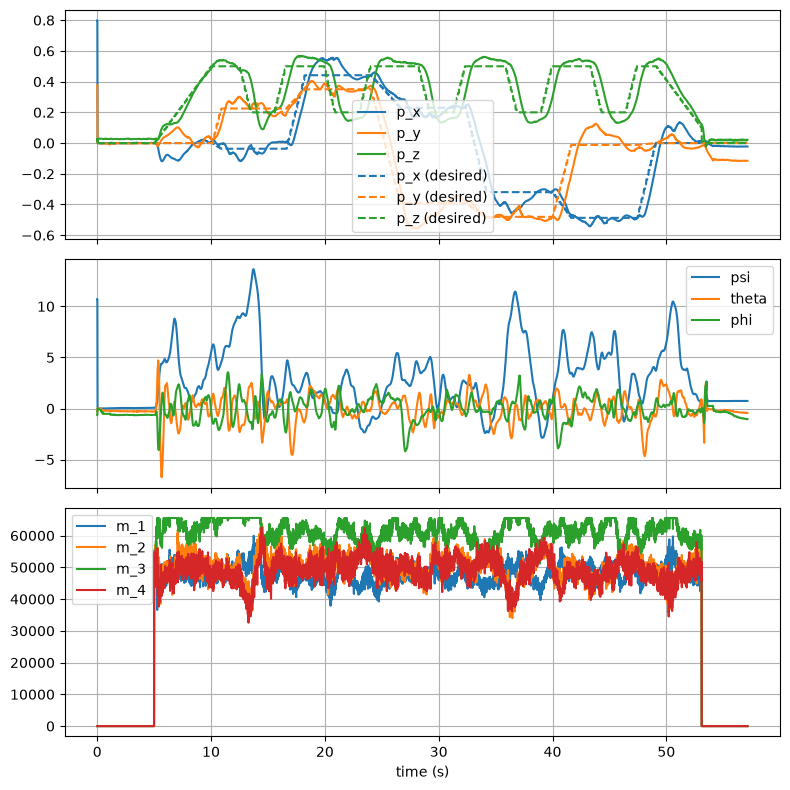

In [980]:
fig, (ax_pos, ax_ori, ax_pow) = plt.subplots(3, 1, figsize=(8, 8), sharex=True, tight_layout=True)
px = ax_pos.plot(t, p_x, label=f'p_x')
py = ax_pos.plot(t, p_y, label=f'p_y')
pz = ax_pos.plot(t, p_z, label=f'p_z')
ax_pos.plot(t, p_x_des, '--', label=f'p_x (desired)', color=px[0].get_color())
ax_pos.plot(t, p_y_des, '--', label=f'p_y (desired)', color=py[0].get_color())
ax_pos.plot(t, p_z_des, '--', label=f'p_z (desired)', color=pz[0].get_color())
ax_pos.legend()
ax_pos.grid()
ax_ori.plot(t, psi, label='psi')
ax_ori.plot(t, theta, label='theta')
ax_ori.plot(t, phi, label='phi')
ax_ori.legend()
ax_ori.grid()
ax_pow.plot(t, m_1, label='m_1')
ax_pow.plot(t, m_2, label='m_2')
ax_pow.plot(t, m_3, label='m_3')
ax_pow.plot(t, m_4, label='m_4')
ax_pow.legend()
ax_pow.grid()
ax_pow.set_xlabel('time (s)')
plt.show()

Show the gains that were used to produce these results.

In [981]:
show_gains(filename)

Control gains, designed 2026-11-09T12:29:37:
tau_x_cmd:     eq   0.0000    p_y  -0.0068    phi   0.0109    v_y  -0.0039    w_x   0.0012  tau_x   2.2776    e_y  -0.0033
tau_y_cmd:     eq   0.0000    p_x   0.0068  theta   0.0109    v_x   0.0038    w_y   0.0012  tau_y   2.2907    e_x   0.0033
    tau_z:     eq   0.0000    psi   0.0013    w_z   0.0003
      f_z:     eq   0.3139    p_z   0.2018    v_z   0.1152    e_z   0.0843


# 6. Summarize results

In [982]:
# Sync mocap data with drone data (must happen before truncation)
data_mocap = sync_data_mocap(
    raw_data_mocap,
    data_drone['time'],
    data_drone['stateEstimate.z'],
    do_transform=True,
)

only_in_flight(data_drone, data_mocap=data_mocap, t_interval=10.)

# Re-parse data so RMSE uses only the truncated in-flight interval
t = data_drone['time']
p_x = data_drone['stateEstimate.x']
p_y = data_drone['stateEstimate.y']
p_z = data_drone['stateEstimate.z']
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']
psi = np.deg2rad(data_drone['stateEstimate.yaw'])
theta = - np.deg2rad(data_drone['stateEstimate.pitch'])
phi = np.deg2rad(data_drone['stateEstimate.roll'])

p_x_rmse = np.sqrt(np.mean((p_x - p_x_des)**2))
p_y_rmse = np.sqrt(np.mean((p_y - p_y_des)**2))
p_z_rmse = np.sqrt(np.mean((p_z - p_z_des)**2))
psi_rmse = np.sqrt(np.mean((psi - 0.)**2))
theta_rmse = np.sqrt(np.mean((theta - 0.)**2))
phi_rmse = np.sqrt(np.mean((phi - 0.)**2))

# Mocap data (angles already in radians from transform_data_mocap)
p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

p_x_mocap_rmse = np.sqrt(np.mean((p_x_mocap - p_x_des)**2))
p_y_mocap_rmse = np.sqrt(np.mean((p_y_mocap - p_y_des)**2))
p_z_mocap_rmse = np.sqrt(np.mean((p_z_mocap - p_z_des)**2))
psi_mocap_rmse = np.sqrt(np.mean((psi_mocap - 0.)**2))
theta_mocap_rmse = np.sqrt(np.mean((theta_mocap - 0.)**2))
phi_mocap_rmse = np.sqrt(np.mean((phi_mocap - 0.)**2))

# key_changes = 'None (controller from Lab 5)'
print(f'| {flight_number} | {p_x_rmse:.3f} | {p_y_rmse:.3f} | {p_z_rmse:.3f} | {psi_rmse:.3f} | {theta_rmse:.3f} | {phi_rmse:.3f} | {key_changes} |')
print(f'| {flight_number} (mocap) | {p_x_mocap_rmse:.3f} | {p_y_mocap_rmse:.3f} | {p_z_mocap_rmse:.3f} | {psi_mocap_rmse:.3f} | {theta_mocap_rmse:.3f} | {phi_mocap_rmse:.3f} | {key_changes} |')

# Store this flight's RMSE values [p_x, p_y, p_z, psi, theta, phi]
try:
    flight_rmse
except NameError:
    flight_rmse = {}
flight_rmse[flight_number] = [p_x_rmse, p_y_rmse, p_z_rmse, psi_rmse, theta_rmse, phi_rmse]

# Store this flight's mocap RMSE values [p_x, p_y, p_z, psi, theta, phi]
try:
    flight_rmse_mocap
except NameError:
    flight_rmse_mocap = {}
flight_rmse_mocap[flight_number] = [p_x_mocap_rmse, p_y_mocap_rmse, p_z_mocap_rmse, psi_mocap_rmse, theta_mocap_rmse, phi_mocap_rmse]
flight_rmse, flight_rmse_mocap

| 43 | 0.067 | 0.096 | 0.083 | 0.048 | 0.018 | 0.022 | def |
| 43 (mocap) | 0.064 | 0.079 | 0.078 | 0.036 | 0.020 | 0.023 | def |


({43: [np.float64(0.06680122838657522),
   np.float64(0.09552475262628544),
   np.float64(0.0827100294047875),
   np.float64(0.04753708442875371),
   np.float64(0.018390510256050662),
   np.float64(0.02228395861663076)]},
 {43: [np.float64(0.0639984549927047),
   np.float64(0.07875839384590001),
   np.float64(0.07834729498687192),
   np.float64(0.03624830633899252),
   np.float64(0.01996167905742136),
   np.float64(0.02305278586337458)]})

In [983]:
# Verify requirements are met, beter performance than benchmark
rmse_names = ['p_x', 'p_y', 'p_z', 'psi', 'theta', 'phi']

# Default controller RMSE values (BENCHMARK row of the table above)
benchmark_rmse = [0.021, 0.020, 0.053, 0.058, 0.031, 0.026]
benchmark_rmse = [0.021, 0.026, 0.546, 0.072, 0.024, 0.031]


def evaluate_flight(custom_rmse, benchmark_rmse=benchmark_rmse):
    # mu_k = RMSE (custom) / RMSE (default) for each k, mu = worst-case ratio
    mu_k = np.array(custom_rmse) / np.array(benchmark_rmse)
    mu = np.max(mu_k)
    grade = min(20. / mu, 40.)
    for name, ratio in zip(rmse_names, mu_k):
        print(f'  mu_{name:5s} = {ratio:8.3f}  {"OK" if ratio <= 1. else "WORSE"}')
    print(f'  mu = max(mu_k) = {mu:.3f} (worst: {rmse_names[np.argmax(mu_k)]})')
    print(f'  requirements met (mu <= 1): {mu <= 1.}')
    print(f'  grade = min(20 / mu, 40) = {grade:.2f} points')
    return mu, grade

num_best_runs = 0
num_recent_runs = 2

# Score every stored run; lower worst-case RMSE ratio is better.
flight_scores = {
    n: float(np.max(np.array(rmse) / np.array(benchmark_rmse)))
    for n, rmse in flight_rmse.items()
}
best_runs = sorted(flight_scores, key=flight_scores.get)[:num_best_runs]
recent_runs = list(flight_rmse)[-num_recent_runs:]

print(f'Evaluated {len(flight_scores)} stored flights.')
print(f'Best {len(best_runs)} flights (lowest worst-case ratio first):')
for n in best_runs:
    label = f' (also among last {num_recent_runs})' if n in recent_runs else ''
    print(f'Flight {n}:{label}')
    evaluate_flight(flight_rmse[n])

print(f'Last {len(recent_runs)} flights (excluding best flights shown above):')
for n in recent_runs:
    if n not in best_runs:
        print(f'Flight {n}:')
        evaluate_flight(flight_rmse[n])


Evaluated 1 stored flights.
Best 0 flights (lowest worst-case ratio first):
Last 1 flights (excluding best flights shown above):
Flight 43:
  mu_p_x   =    3.181  WORSE
  mu_p_y   =    3.674  WORSE
  mu_p_z   =    0.151  OK
  mu_psi   =    0.660  OK
  mu_theta =    0.766  OK
  mu_phi   =    0.719  OK
  mu = max(mu_k) = 3.674 (worst: p_y)
  requirements met (mu <= 1): False
  grade = min(20 / mu, 40) = 5.44 points


# 7. Enable smooth motion

## 7.1 Results of non-smooth square flight

## 7.2 Results of smooth square flight

## 7.3 Comparison between non-smooth and smooth flight

| Flight | RMSE in $p_x$ | RMSE in $p_y$ | RMSE in $p_z$ | RMSE in $\psi$ | RMSE in $\theta$ | RMSE in $\phi$ |
| :--: | :--: | :--: | :--: | :--: | :--: | :--: |
| 43 | 0.017 | 0.024 | 0.046 | 0.041 | 0.010 | 0.016 | None (controller from Lab 5) |
| Square | 0.177 | 0.173 | 0.046 | 0.027 | 0.063 | 0.065 | def |
| Smooth Square 04| 0.109 | 0.091 | 0.042 | 0.036 | 0.018 | 0.013 | def |
| Smooth Square DRONE | 0.103 | 0.084 | 0.046 | 0.031 | 0.018 | 0.013 | def |
| Smooth Square MOCAP | 0.078 | 0.072 | 0.046 | 0.034 | 0.023 | 0.014 | def |



In [984]:
mediaspace('https://mediaspace.illinois.edu/media/t/1_2iy71iky')